# Extranjeros entre quienes cotizan y quienes cobran prestaciones

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "extranjeros-cotizantes-perceptores"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Extranjeros entre quienes cotizan y quienes cobran prestaciones"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # con `categorias`: una serie por grupo y sin serie `espana` (vista de categorías)
VISTA = "categorias"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de nacionalidad extranjera en cada grupo"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de personas de nacionalidad extranjera en cada grupo: en la población (total, de 15 a 64 años y de 65 o más), entre los afiliados a la Seguridad Social y entre quienes cobran cada prestación. Sirve para comparar el peso de los extranjeros entre quienes cotizan y entre quienes cobran con su peso en la población de cada edad.

**Cómo se lee.** Si los extranjeros son el 14 % de los afiliados y el 13 % de los beneficiarios de una prestación, su peso entre quienes la cobran es parecido al que tienen entre quienes cotizan.

**Limitaciones.**
- **Nacionalidad, no país de nacimiento:** quien obtiene la nacionalidad española deja de contar como extranjero, así que las nacionalizaciones bajan los porcentajes (ver `poblacion-nacida-extranjero`).
- **Personas, no euros:** ningún organismo de la lista de fuentes publica las cotizaciones pagadas o las prestaciones cobradas por nacionalidad. La contribución fiscal neta de la población inmigrante se trata en la evidencia (OCDE, *International Migration Outlook 2021*, cap. 4).
- **Edad:** la población extranjera es más joven que la española; buena parte de la diferencia entre su peso entre los afiliados y entre los pensionistas se explica por la edad, como muestra la diferencia entre la población de 15 a 64 años y la de 65 o más.
- **Unidades distintas:** el ingreso mínimo vital se cuenta por hogares (la nacionalidad es la del titular); el resto, por personas.
- **Categoría sin dato:** el Ministerio de Inclusión publica las pensiones contributivas por país de residencia del pensionista, no por nacionalidad, así que queda vacía.
- **Pensiones no contributivas, solo un año:** el IMSERSO da la nacionalidad de los pensionistas en el informe en PDF del perfil del pensionista, y su página solo enlaza el del último año.
- **Edades de la población:** el INE publica la población por nacionalidad en grupos quinquenales; se usa la de 15 a 64 años en lugar de la de 16 a 64.

## 2. Descarga

1. **Población por nacionalidad y edad:** INE, Estadística Continua de Población (tabla 82104), población residente total y de nacionalidad extranjera por grupos de edad, a 1 de enero (series `ECP`).
2. **Afiliados:** Ministerio de Inclusión, afiliados medios extranjeros y totales (ficheros anuales desde 2022, `lib/inclusion.py`).
3. **Prestaciones por desempleo:** SEPE, beneficiarios totales y extranjeros, media anual (informe de diciembre, tablas BP-1.1 y BP-1.4, `lib/sepe.py`).
4. **Ingreso mínimo vital:** Ministerio de Inclusión, titulares por nacionalidad en la nómina de diciembre (dosier, hoja 1.5, `lib/inclusion.py`).

In [ ]:
import sys
from datetime import date
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd
import requests

from lib import estilos
from lib import imserso, inclusion, ine, sepe
from lib._http import pedir
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

ANIO_ACTUAL = date.today().year

# INE, Estadística Continua de Población: códigos de serie (total y extranjera, ambos sexos) por grupo de edad
GRUPOS = {  # grupo: (total, extranjera)
    "00-04": ("ECP4958", "ECP698"), "05-09": ("ECP4955", "ECP695"), "10-14": ("ECP4952", "ECP692"),
    "15-19": ("ECP4949", "ECP689"), "20-24": ("ECP4946", "ECP686"), "25-29": ("ECP4943", "ECP683"),
    "30-34": ("ECP4940", "ECP680"), "35-39": ("ECP4937", "ECP677"), "40-44": ("ECP4934", "ECP674"),
    "45-49": ("ECP4931", "ECP671"), "50-54": ("ECP4928", "ECP668"), "55-59": ("ECP4925", "ECP665"),
    "60-64": ("ECP4922", "ECP662"), "65-69": ("ECP4919", "ECP659"), "70-74": ("ECP4916", "ECP656"),
    "75-79": ("ECP4913", "ECP653"), "80-84": ("ECP4910", "ECP650"), "85-89": ("ECP4907", "ECP647"),
    "90+": ("ECP4904", "ECP644"),
}


def ine_1_enero(codigo):
    """Valor a 1 de enero de cada año (primera observación del año) de una serie de la ECP."""
    r = pedir(requests.Session(), f"{ine.BASE}/{codigo}", {"date": f"{DESDE}0101:{ANIO_ACTUAL}1231"},
              error_cls=ine.IneError, etiqueta=codigo, mensaje=lambda r: r.text[:200])
    obs = ine.parsear_serie(r.text, codigo).dropna(subset=["valor"])
    return obs.sort_values("orden").groupby("anio")["valor"].first()


poblacion = {g: (ine_1_enero(t), ine_1_enero(e)) for g, (t, e) in GRUPOS.items()}
afil, fuentes_afil = inclusion.get_afiliacion_extranjeros()
desempleo, fuentes_desempleo = sepe.get_beneficiarios(range(2017, ANIO_ACTUAL))
imv, fuentes_imv = inclusion.get_imv_titulares(range(2024, ANIO_ACTUAL))
# IMSERSO: pensionistas no contributivos por nacionalidad, solo el año del último perfil publicado (PDF)
pnc, fuentes_pnc = imserso.get_nacionalidad()

## 3. Transformación

Porcentaje de nacionalidad extranjera en cada grupo y año: extranjeros entre el total, por 100. Cada grupo es una categoría (`categorias`), con su serie y su fuente; la de pensiones contributivas va sin dato.

In [ ]:
def suma(grupos, cual):
    return pd.concat([poblacion[g][cual] for g in grupos], axis=1).dropna().sum(axis=1)


TODAS = list(GRUPOS)
EDAD_TRABAJO = [g for g in GRUPOS if 15 <= int(g[:2]) < 65]
MAYORES = [g for g in GRUPOS if int(g[:2]) >= 65]
serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]

CATEGORIAS = {
    "poblacion-total": ("Población total", suma(TODAS, 1) / suma(TODAS, 0) * 100),
    "poblacion-15-64": ("Población de 15 a 64 años", suma(EDAD_TRABAJO, 1) / suma(EDAD_TRABAJO, 0) * 100),
    "poblacion-65-mas": ("Población de 65 años o más", suma(MAYORES, 1) / suma(MAYORES, 0) * 100),
    "afiliados": ("Afiliados a la Seguridad Social", serie(afil, "afiliados_extranjeros") / serie(afil, "afiliados_total") * 100),
    "pensiones-contributivas": ("Pensiones contributivas", pd.Series(dtype=float)),
    "pensiones-no-contributivas": ("Pensiones no contributivas",
                                   (serie(pnc, "pensionistas_ue_eee") + serie(pnc, "pensionistas_otras"))
                                   / serie(pnc, "pensionistas_total") * 100),
    "prestaciones-desempleo": ("Prestaciones y subsidios por desempleo",
                               serie(desempleo, "beneficiarios_extranjeros") / serie(desempleo, "beneficiarios") * 100),
    "ingreso-minimo-vital": ("Ingreso mínimo vital (hogares)",
                             serie(imv, "imv_titulares_extranjeros") / serie(imv, "imv_titulares") * 100),
}
tabla = pd.DataFrame({nombre: s for nombre, s in CATEGORIAS.values()}).sort_index()
con_dato = [nombre for nombre, s in CATEGORIAS.values() if not s.empty]
ULTIMO_COMUN = int(tabla[con_dato].dropna().index.max())
print("Último año con dato en todas las categorías con datos:", ULTIMO_COMUN)
display(tabla.loc[2017:].round(1))

# DataFrame estándar: una serie por categoría; las que no tienen dato llevan una fila vacía para que existan
ANIOS = tabla.index
df = pd.concat([
    pd.DataFrame({"serie": clave, "periodo": ANIOS, "valor": s.reindex(ANIOS).values})
    for clave, (_, s) in CATEGORIAS.items()
], ignore_index=True)
assert df["valor"].dropna().between(0, 100).all(), "porcentaje fuera de rango"

HOY = fuentes_afil[0].fecha_consulta
URL_ECP = "https://www.ine.es/jaxiT3/Tabla.htm?t=82104"
por_serie = lambda fs, s: next(f for f in fs if f.serie == s)  # noqa: E731
fuentes = [
    FuenteMeta("poblacion-total", ine.ORGANISMO, "Estadística Continua de Población, tabla 82104 (total y extranjera, todas las edades)", URL_ECP, HOY),
    FuenteMeta("poblacion-15-64", ine.ORGANISMO, "Estadística Continua de Población, tabla 82104 (total y extranjera, de 15 a 64 años)", URL_ECP, HOY),
    FuenteMeta("poblacion-65-mas", ine.ORGANISMO, "Estadística Continua de Población, tabla 82104 (total y extranjera, de 65 años o más)", URL_ECP, HOY),
    FuenteMeta("afiliados", inclusion.ORGANISMO, por_serie(fuentes_afil, "afiliados_extranjeros").dataset_codigo,
               por_serie(fuentes_afil, "afiliados_extranjeros").url, HOY),
    FuenteMeta("pensiones-contributivas", inclusion.ORGANISMO,
               "Pensiones contributivas en vigor: sin desglose por nacionalidad (solo por país de residencia)",
               f"{inclusion.BASE}/wps/portal/wss/internet/EstadisticasPresupuestosEstudios/Estadisticas", HOY),
    FuenteMeta("pensiones-no-contributivas", imserso.ORGANISMO,
               por_serie(fuentes_pnc, "pensionistas_total").dataset_codigo.replace(
                   "nacionalidad del pensionista", "pensionistas de la UE y el EEE y de otras nacionalidades entre el total de pensionistas"),
               por_serie(fuentes_pnc, "pensionistas_total").url, HOY),
    FuenteMeta("prestaciones-desempleo", sepe.ORGANISMO,
               "Informe de prestaciones por desempleo de diciembre, BP-1.1 y BP-1.4 (media anual)",
               por_serie(fuentes_desempleo, "beneficiarios").url, HOY),
    FuenteMeta("ingreso-minimo-vital", inclusion.ORGANISMO, por_serie(fuentes_imv, "imv_titulares_extranjeros").dataset_codigo,
               por_serie(fuentes_imv, "imv_titulares_extranjeros").url, HOY),
]

Último año con dato en todas las categorías con datos: 2025


,Población total,Población de 15 a 64 años,Población de 65 años o más,Afiliados a la Seguridad Social,Pensiones contributivas,Pensiones no contributivas,Prestaciones y subsidios por desempleo,Ingreso mínimo vital (hogares)
2017,9.5,11.2,3.8,NaN,NaN,NaN,9.7,NaN
2018,9.8,11.6,3.8,NaN,NaN,NaN,10.2,NaN
2019,10.3,12.3,3.9,NaN,NaN,NaN,10.3,NaN
2020,11.1,13.1,4.0,NaN,NaN,NaN,12.2,NaN
2021,11.4,13.5,4.2,NaN,NaN,NaN,11.7,NaN
2022,11.6,13.7,4.5,11.9,NaN,NaN,10.4,NaN
2023,12.7,15.0,4.9,12.7,NaN,NaN,11.1,NaN
2024,13.4,15.9,5.1,13.4,NaN,NaN,11.9,17.6
2025,14.1,16.7,5.4,14.0,NaN,8.3,12.7,17.5
2026,14.6,17.5,5.7,NaN,NaN,NaN,NaN,NaN


### Notas

In [ ]:
ANIO_PNC = int(pnc["periodo"].max())


def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


NOTAS = [
    "Población: INE, Estadística Continua de Población, población residente a 1 de enero por nacionalidad y grupo "
    "de edad (la total es la suma de todos los grupos); la población en edad de trabajar es la de 15 a 64 años porque el INE la publica en grupos quinquenales.",
    "Afiliados: Ministerio de Inclusión, Seguridad Social y Migraciones, afiliados medios extranjeros y totales, media "
    f"anual (ficheros anuales desde {int(afil['periodo'].min())}).",
    "Prestaciones por desempleo: SEPE, beneficiarios de prestaciones contributivas, subsidios, renta agraria, subsidio "
    "agrario y renta activa de inserción, totales y extranjeros, media anual.",
    "Ingreso mínimo vital: Ministerio de Inclusión, hogares titulares por nacionalidad del titular en la nómina de "
    "diciembre; el resto de las categorías cuenta personas.",
    f"Pensiones no contributivas: IMSERSO, pensionistas de jubilación e incapacidad en diciembre de {ANIO_PNC} según "
    "su nacionalidad (de otro país de la UE o del Espacio Económico Europeo, o de otro país), del informe en PDF del "
    "perfil del pensionista; solo hay dato del año del último informe.",
    "Pensiones contributivas: sin dato. El Ministerio de Inclusión publica las pensiones contributivas por país de "
    "residencia, no por nacionalidad.",
    "Cuenta la nacionalidad y no el país de nacimiento, y mide personas y no euros: ningún organismo publica las "
    "cotizaciones pagadas por nacionalidad.",
    "La diferencia entre la población de 15 a 64 años y la de 65 o más refleja la menor edad de la población "
    "extranjera, que explica buena parte de las diferencias entre afiliados y pensionistas.",
]
for n in NOTAS:
    print("-", n)

- Población: INE, Estadística Continua de Población, población residente a 1 de enero por nacionalidad y grupo de edad (la total es la suma de todos los grupos); la población en edad de trabajar es la de 15 a 64 años porque el INE la publica en grupos quinquenales.
- Afiliados: Ministerio de Inclusión, Seguridad Social y Migraciones, afiliados medios extranjeros y totales, media anual (ficheros anuales desde 2022).
- Prestaciones por desempleo: SEPE, beneficiarios de prestaciones contributivas, subsidios, renta agraria, subsidio agrario y renta activa de inserción, totales y extranjeros, media anual.
- Ingreso mínimo vital: Ministerio de Inclusión, hogares titulares por nacionalidad del titular en la nómina de diciembre; el resto de las categorías cuenta personas.
- Pensiones no contributivas: IMSERSO, pensionistas de jubilación e incapacidad en diciembre de 2025 según su nacionalidad (de otro país de la UE o del Espacio Económico Europeo, o de otro país), del informe en PDF del perfil

## 4. Visualización

Una barra por categoría en el último año con dato de todas las categorías que tienen alguno, como la vista de categorías de la web (`vista: "categorias"`).

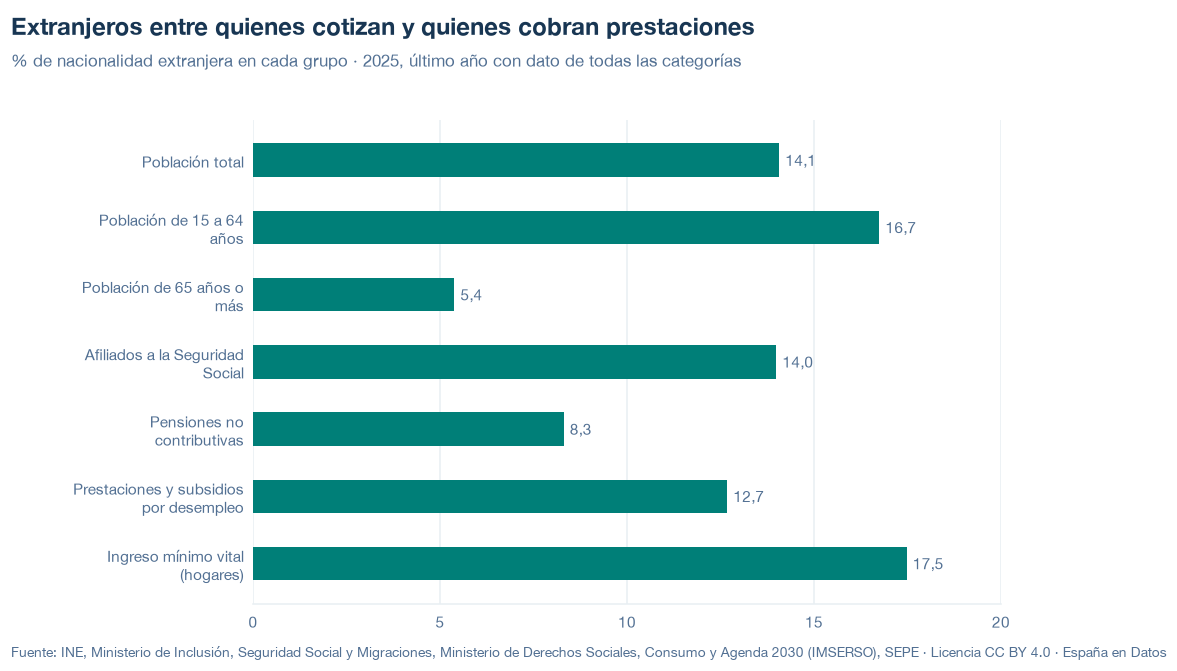

In [ ]:
NOMBRES = {clave: nombre for clave, (nombre, _) in CATEGORIAS.items()}
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, categorias=NOMBRES,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, con una columna por categoría.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, categorias=NOMBRES,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/extranjeros-cotizantes-perceptores.json y data/extranjeros-cotizantes-perceptores.csv


## 6. Fuentes, notas y licencia

- INE, Estadística Continua de Población (tabla 82104).
- Ministerio de Inclusión, Seguridad Social y Migraciones: afiliados medios extranjeros; ingreso mínimo vital (dosier por comunidad autónoma y provincia).
- SEPE, informe mensual de prestaciones por desempleo (BP-1.1 y BP-1.4).

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.